**0. IMPORT & ĐỌC DỮ LIỆU**

In [ ]:
# Thư viện xử lý dữ liệu
import pandas as pd
import numpy as np

# Thư viện trực quan hóa
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")


In [ ]:
# Kết nối Google Drive để đọc file dữ liệu
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Đọc file CSV từ Google Drive
df=pd.read_csv('/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/Zomato Dataset.csv')


In [ ]:
#Xem 5 dòng đầu tiên
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


# **II. TIỀN XỬ LÝ**

In [ ]:
# =========================
# BẢNG 1 – THÔNG TIN TỔNG QUAN TẬP DỮ LIỆU
# =========================

n_rows = df.shape[0]
n_cols = df.shape[1]

num_cols = df.select_dtypes(include=["int64", "float64"]).columns
cat_cols = df.select_dtypes(include=["object", "category"]).columns
time_cols = df.select_dtypes(include=["datetime64[ns]"]).columns

summary_table = pd.DataFrame({
    "Chỉ tiêu": [
        "Số dòng (Observations)",
        "Số cột (Features)",
        "Số biến số (Numerical)",
        "Số biến phân loại (Categorical)",
        "Số biến thời gian (Datetime)"
    ],
    "Giá trị": [
        n_rows,
        n_cols,
        len(num_cols),
        len(cat_cols),
        len(time_cols)
    ]
})

summary_table


,Chỉ tiêu,Giá trị
0,Số dòng (Observations),45584
1,Số cột (Features),20
2,Số biến số (Numerical),9
3,Số biến phân loại (Categorical),11
4,Số biến thời gian (Datetime),0


In [ ]:
# =========================
# BẢNG 2 – THỐNG KÊ GIÁ TRỊ THIẾU
# =========================

missing_table = pd.DataFrame({
    "Tên biến": df.columns,
    "Số giá trị thiếu": df.isnull().sum(),
    "Tỷ lệ thiếu (%)": (df.isnull().sum() / len(df) * 100).round(2)
})

# Chỉ giữ các biến có missing value
missing_table = missing_table[missing_table["Số giá trị thiếu"] > 0]

# Sắp xếp giảm dần theo số lượng thiếu
missing_table = missing_table.sort_values(
    by="Số giá trị thiếu",
    ascending=False
).reset_index(drop=True)

missing_table


,Tên biến,Số giá trị thiếu,Tỷ lệ thiếu (%)
0,Delivery_person_Ratings,1908,4.190
1,Delivery_person_Age,1854,4.070
2,Time_Orderd,1731,3.800
3,City,1200,2.630
4,multiple_deliveries,993,2.180
5,Weather_conditions,616,1.350
6,Road_traffic_density,601,1.320
7,Festival,228,0.500


**1. Làm sạch tên cột**

In [ ]:
# 1. Chuẩn hóa tên cột
# Xem tên cột ban đầu
print("Tên cột trước khi chuẩn hóa:")
print(df.columns)

# Chuẩn hóa tên cột
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
)

df = df.rename(columns={
    "time_orderd": "time_ordered",
    "weather_conditions": "weather",
    "road_traffic_density": "traffic",
    "time_taken_min": "time_taken"
})


print("Tên cột sau khi chuẩn hóa:")
print(df.columns.tolist())


# 2. Loại bỏ khoảng trắng thừa trong các cột dạng object
for col in df.select_dtypes(include="object"):
    df[col] = df[col].str.strip()

print("\nKiểm tra một vài giá trị categorical:")
for col in ["weather_conditions", "road_traffic_density", "city"]:
    if col in df.columns:
        print(f"{col}:")
        print(df[col].unique()[:5])



Tên cột trước khi chuẩn hóa:
Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)'],
      dtype='object')
Tên cột sau khi chuẩn hóa:
['id', 'delivery_person_id', 'delivery_person_age', 'delivery_person_ratings', 'restaurant_latitude', 'restaurant_longitude', 'delivery_location_latitude', 'delivery_location_longitude', 'order_date', 'time_ordered', 'time_order_picked', 'weather', 'traffic', 'vehicle_condition', 'type_of_order', 'type_of_vehicle', 'multiple_deliveries', 'festival', 'city', 'time_taken']

Kiểm tra một vài giá trị categorical:
city:
['Metropolitian' 'Urban' 'Semi-Urban' nan]


**2. Xóa dữ liệu trùng lặp**

In [ ]:
# Kiểm tra số dòng trùng
dup_count = df.duplicated().sum()
print("Số dòng trùng hoàn toàn:", dup_count)

# Xóa nếu có
df = df.drop_duplicates().reset_index(drop=True)

# Kiểm tra sau khi xóa
print("Số dòng sau khi loại bỏ trùng:", df.shape[0])

Số dòng trùng hoàn toàn: 0
Số dòng sau khi loại bỏ trùng: 45584


**3. Ổn định giá trị và kiểu dữ liệu thô**

In [ ]:
# 1. Sửa lỗi "NaN" dạng chuỗi
df.replace("NaN", np.nan, inplace=True)
df.replace("nan", np.nan, inplace=True)
# # Kiểm tra lại số lượng missing sau khi chuẩn hóa
df.isna().sum()

,0
id,0
delivery_person_id,0
delivery_person_age,1854
delivery_person_ratings,1908
restaurant_latitude,0
restaurant_longitude,0
delivery_location_latitude,0
delivery_location_longitude,0
order_date,0
time_ordered,1731


In [ ]:
# 2. Chuẩn hóa biến ngày (order_date)
# Xem thử vài giá trị ban đầu của order_date (đang là object)
print(df["order_date"].head())

# Chuyển order_date sang kiểu datetime
df["order_date"] = pd.to_datetime(
    df["order_date"],
    dayfirst=True,
    errors="coerce"
)

# Kiểm tra kiểu dữ liệu và số giá trị bị lỗi sau khi convert
print(df["order_date"].dtype)
print(df["order_date"].isna().sum())

0    12-02-2022
1    13-02-2022
2    04-03-2022
3    13-02-2022
4    14-02-2022
Name: order_date, dtype: object
datetime64[ns]
0


In [ ]:
# 3. Làm sạch dữ liệu giờ (time_ordered, time_order_picked)
# Xem trước dữ liệu giờ gốc (thường có lỗi Excel time, giờ > 24, khoảng trắng...)
print(df[["time_ordered", "time_order_picked"]].head(10))

def clean_time(col):
    # Ép về string nhưng giữ NaN
    col = col.astype("string").str.strip()

    # 1. Chuẩn hóa các giá trị rác thành NaN
    col = col.replace(["nan", "NaN", "None", "", " "], pd.NA)

    # 2. Loại Excel time dạng 0.xxxx
    col = col.mask(col.str.match(r"^\d+\.\d+$", na=False), pd.NA)

    # 3. Chỉ giữ dạng HH:MM
    col = col.mask(~col.str.match(r"^\d{1,2}:\d{2}$", na=False), pd.NA)

    # 4. Chuẩn hóa giờ >= 24
    def fix_hour(t):
        if pd.isna(t):
            return pd.NA
        try:
            h, m = t.split(":")
            h = int(h) % 24
            m = int(m)
            return f"{h:02d}:{m:02d}"
        except:
            return pd.NA

    col = col.apply(fix_hour)
    return col

# Áp dụng làm sạch cho hai cột giờ
df["time_ordered"] = clean_time(df["time_ordered"])
df["time_order_picked"] = clean_time(df["time_order_picked"])
# Kiểm tra kết quả sau khi làm sạch
print(df[["time_ordered", "time_order_picked"]].head(10))
df[["time_ordered", "time_order_picked"]].isna().sum()


  time_ordered time_order_picked
0        21:55             22:10
1        14:55             15:05
2        17:30             17:40
3        09:20             09:30
4        19:50             20:05
5        20:25             20:35
6        14:55             15:10
7        20:30             20:40
8        20:40             20:50
9        21:15             21:30
  time_ordered time_order_picked
0        21:55             22:10
1        14:55             15:05
2        17:30             17:40
3        09:20             09:30
4        19:50             20:05
5        20:25             20:35
6        14:55             15:10
7        20:30             20:40
8        20:40             20:50
9        21:15             21:30


,0
time_ordered,5799
time_order_picked,5007


**4. Tạo trục thời gian order_timestamp & picked_timestamp**

In [ ]:
# 1. Tạo order_timestamp
# Ghép order_date + time_ordered
df["order_timestamp"] = pd.to_datetime(
    df["order_date"].astype(str) + " " + df["time_ordered"].astype(str),
    errors="coerce"
)

# Kiểm tra nhanh
print(df["order_timestamp"].head())
print("NaN order_timestamp:", df["order_timestamp"].isna().sum())

0   2022-02-12 21:55:00
1   2022-02-13 14:55:00
2   2022-03-04 17:30:00
3   2022-02-13 09:20:00
4   2022-02-14 19:50:00
Name: order_timestamp, dtype: datetime64[ns]
NaN order_timestamp: 5799


In [ ]:
# 2. Tạo picked_timestamp
# Ghép order_date + time_order_picked
df["picked_timestamp"] = pd.to_datetime(
    df["order_date"].astype(str) + " " + df["time_order_picked"].astype(str),
    errors="coerce"
)

# Kiểm tra nhanh
print(df["picked_timestamp"].head())
print("NaN picked_timestamp:", df["picked_timestamp"].isna().sum())

0   2022-02-12 22:10:00
1   2022-02-13 15:05:00
2   2022-03-04 17:40:00
3   2022-02-13 09:30:00
4   2022-02-14 20:05:00
Name: picked_timestamp, dtype: datetime64[ns]
NaN picked_timestamp: 5007


In [ ]:
# Lấy ra những dòng mà hai mốc thời gian đều hợp lệ
tmp = df.dropna(subset=["order_timestamp", "picked_timestamp"])
# Tại đó, kiểm tra logic thời gian, picked time không được nhỏ hơn order time
(tmp["picked_timestamp"] < tmp["order_timestamp"]).value_counts()


,count
False,35407


In [ ]:
df = df.dropna(subset=["order_timestamp", "picked_timestamp"]).reset_index(drop=True)

print("Số dòng sau khi drop:", len(df))


Số dòng sau khi drop: 35407


In [ ]:
# 3. Sửa lỗi lấy hàng qua ngày hôm sau
# (picked_timestamp < order_timestamp)
mask_next_day = df["picked_timestamp"] < df["order_timestamp"]

# Nếu lấy hàng sớm hơn thời điểm đặt → cộng thêm 1 ngày
df.loc[mask_next_day, "picked_timestamp"] += pd.Timedelta(days=1)

# Kiểm tra số dòng bị điều chỉnh
print("Số đơn lấy hàng qua ngày hôm sau:", mask_next_day.sum())

Số đơn lấy hàng qua ngày hôm sau: 0


In [ ]:
# 4. Kiểm tra logic thời gian
# picked_timestamp phải >= order_timestamp
(df["picked_timestamp"] >= df["order_timestamp"]).value_counts()

,count
True,35407


**5. Sort theo thời gian & Reset index**

In [ ]:
# 1. Sort dữ liệu theo order_timestamp
df = df.sort_values(by="order_timestamp")

# Kiểm tra nhanh
print(df[["order_timestamp", "picked_timestamp"]].head())
print(df[["order_timestamp", "picked_timestamp"]].tail(10))

          order_timestamp    picked_timestamp
18643 2022-02-11 08:10:00 2022-02-11 08:15:00
23764 2022-02-11 08:10:00 2022-02-11 08:20:00
14384 2022-02-11 08:10:00 2022-02-11 08:20:00
15867 2022-02-11 08:15:00 2022-02-11 08:30:00
18920 2022-02-11 08:15:00 2022-02-11 08:25:00
          order_timestamp    picked_timestamp
6531  2022-04-06 23:40:00 2022-04-06 23:50:00
8254  2022-04-06 23:45:00 2022-04-06 23:50:00
8225  2022-04-06 23:45:00 2022-04-06 23:55:00
16350 2022-04-06 23:45:00 2022-04-06 23:55:00
26837 2022-04-06 23:45:00 2022-04-06 23:55:00
338   2022-04-06 23:45:00 2022-04-06 23:55:00
20254 2022-04-06 23:45:00 2022-04-06 23:50:00
12980 2022-04-06 23:50:00 2022-04-06 23:55:00
32987 2022-04-06 23:50:00 2022-04-06 23:55:00
1312  2022-04-06 23:50:00 2022-04-06 23:55:00


In [ ]:
# 2. Reset index sau khi sort
df = df.reset_index(drop=True)

# Kiểm tra index
print(df.index[:10])

RangeIndex(start=0, stop=10, step=1)


In [ ]:
# 3.  Kiểm tra lại thứ tự thời gian
# order_timestamp phải tăng dần
(df["order_timestamp"].diff().iloc[1:].dt.total_seconds() >= 0).value_counts()

,count
order_timestamp,
True,35406


**5. Featuring**

In [ ]:
# 1. Trích xuất thông tin thời gian từ order_timestamp
df["order_hour"] = df["order_timestamp"].dt.hour
df["order_dayofweek"] = df["order_timestamp"].dt.dayofweek
# 0 = Monday, 6 = Sunday

df["order_month"] = df["order_timestamp"].dt.month

# 2. Tạo biến cuối tuần
df["is_weekend"] = df["order_dayofweek"].isin([5, 6]).astype(int)

# Kiểm tra nhanh
print(df[[
    "order_timestamp",
    "order_hour",
    "order_dayofweek",
    "order_month",
    "is_weekend"
]].head(10))


      order_timestamp  order_hour  order_dayofweek  order_month  is_weekend
0 2022-02-11 08:10:00           8                4            2           0
1 2022-02-11 08:10:00           8                4            2           0
2 2022-02-11 08:10:00           8                4            2           0
3 2022-02-11 08:15:00           8                4            2           0
4 2022-02-11 08:15:00           8                4            2           0
5 2022-02-11 08:15:00           8                4            2           0
6 2022-02-11 08:20:00           8                4            2           0
7 2022-02-11 08:20:00           8                4            2           0
8 2022-02-11 08:20:00           8                4            2           0
9 2022-02-11 08:20:00           8                4            2           0


In [ ]:
# 3. Tạo prep_time (đơn vị: phút)
df["prep_time"] = (
    df["picked_timestamp"] - df["order_timestamp"]
).dt.total_seconds() / 60

# Kiểm tra nhanh
print(df[[
    "order_timestamp",
    "picked_timestamp",
    "prep_time"
]].head(10))

# Thống kê nhanh
print(df["prep_time"].describe())


      order_timestamp    picked_timestamp  prep_time
0 2022-02-11 08:10:00 2022-02-11 08:15:00      5.000
1 2022-02-11 08:10:00 2022-02-11 08:20:00     10.000
2 2022-02-11 08:10:00 2022-02-11 08:20:00     10.000
3 2022-02-11 08:15:00 2022-02-11 08:30:00     15.000
4 2022-02-11 08:15:00 2022-02-11 08:25:00     10.000
5 2022-02-11 08:15:00 2022-02-11 08:20:00      5.000
6 2022-02-11 08:20:00 2022-02-11 08:35:00     15.000
7 2022-02-11 08:20:00 2022-02-11 08:35:00     15.000
8 2022-02-11 08:20:00 2022-02-11 08:25:00      5.000
9 2022-02-11 08:20:00 2022-02-11 08:25:00      5.000
count   35407.000
mean        9.945
std         4.086
min         5.000
25%         5.000
50%        10.000
75%        15.000
max        15.000
Name: prep_time, dtype: float64


In [ ]:
print("1. PHÂN PHỐI CÁC GIÁ TRỊ CỦA PREP_TIME")
print(df["prep_time"].value_counts().sort_index())
print("-" * 50)

print("2. TƯƠNG QUAN GIỮA PREP_TIME VÀ TIME_TAKEN")
# Sử dụng method='spearman' phù hợp cho dữ liệu có phân phối không chuẩn
corr = df[["prep_time", "time_taken"]].corr(method="spearman")
print(corr)
print("-" * 50)

print("3. TRUNG BÌNH THỜI GIAN GIAO HÀNG THEO TỪNG MỨC PREP_TIME")
mean_eta = df.groupby("prep_time")["time_taken"].mean()
print(mean_eta)
print("-" * 50)

print("4. KIỂM CHỨNG VẬT LÝ: TÍNH THỜI GIAN DI CHUYỂN (TRAVEL TIME)")
# Giả định: Tổng thời gian = Thời gian chuẩn bị + Thời gian di chuyển
# => Thời gian di chuyển = Tổng thời gian - Thời gian chuẩn bị
df["travel_time"] = df["time_taken"] - df["prep_time"]
print(df["travel_time"].describe())

1. PHÂN PHỐI CÁC GIÁ TRỊ CỦA PREP_TIME
prep_time
5.000     12022
10.000    11753
15.000    11632
Name: count, dtype: int64
--------------------------------------------------
2. TƯƠNG QUAN GIỮA PREP_TIME VÀ TIME_TAKEN
            prep_time  time_taken
prep_time       1.000      -0.000
time_taken     -0.000       1.000
--------------------------------------------------
3. TRUNG BÌNH THỜI GIAN GIAO HÀNG THEO TỪNG MỨC PREP_TIME
prep_time
5.000    26.320
10.000   26.438
15.000   26.275
Name: time_taken, dtype: float64
--------------------------------------------------
4. KIỂM CHỨNG VẬT LÝ: TÍNH THỜI GIAN DI CHUYỂN (TRAVEL TIME)
count   35407.000
mean       16.400
std        10.252
min        -5.000
25%         9.000
50%        16.000
75%        23.000
max        49.000
Name: travel_time, dtype: float64


/tmp/ipykernel_730/20993260.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="prep_time", y="time_taken", palette="Set2")
/tmp/ipykernel_730/20993260.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="prep_time", y="time_taken", estimator="mean", palette="Set2", capsize=0.1)


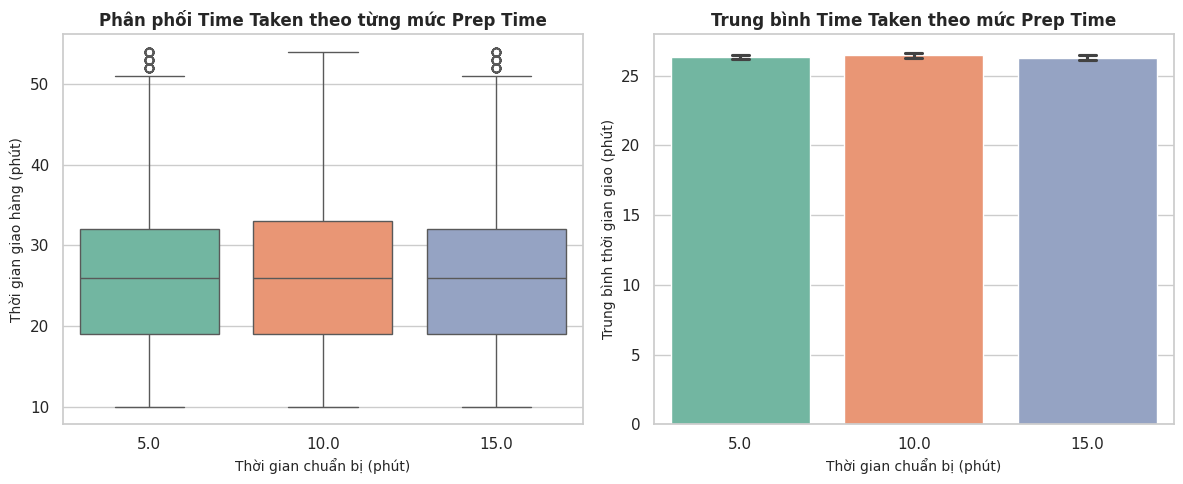

In [ ]:
# Thiết lập kích thước khung hình
plt.figure(figsize=(12, 5))

# Biểu đồ 1: Biểu đồ hộp (Boxplot) xem xét sự phân tán
plt.subplot(1, 2, 1)
sns.boxplot(data=df, x="prep_time", y="time_taken", palette="Set2")
plt.title("Phân phối Time Taken theo từng mức Prep Time", fontsize=12, fontweight='bold')
plt.xlabel("Thời gian chuẩn bị (phút)", fontsize=10)
plt.ylabel("Thời gian giao hàng (phút)", fontsize=10)

# Biểu đồ 2: Biểu đồ cột (Barplot) xem xét giá trị trung bình
plt.subplot(1, 2, 2)
sns.barplot(data=df, x="prep_time", y="time_taken", estimator="mean", palette="Set2", capsize=0.1)
plt.title("Trung bình Time Taken theo mức Prep Time", fontsize=12, fontweight='bold')
plt.xlabel("Thời gian chuẩn bị (phút)", fontsize=10)
plt.ylabel("Trung bình thời gian giao (phút)", fontsize=10)

# Căn chỉnh và hiển thị
plt.tight_layout()
plt.show()

# Xóa biến travel_time sau khi đã kiểm chứng xong để tránh rác dữ liệu
df = df.drop(columns=['travel_time'])

In [ ]:
# 4. Tạo distance (km)
# 4.1 Kiểm tra giá trị lat/long
df[[
    "restaurant_latitude",
    "restaurant_longitude",
    "delivery_location_latitude",
    "delivery_location_longitude"
]].describe()


,restaurant_latitude,restaurant_longitude,delivery_location_latitude,delivery_location_longitude
count,35407.000,35407.000,35407.000,35407.000
mean,17.237,70.793,17.458,70.857
std,7.696,21.080,7.333,21.080
min,-30.903,0.000,0.010,0.010
25%,12.933,73.171,12.986,73.289
50%,18.551,75.898,18.630,76.004
75%,22.728,78.045,22.784,78.104
max,30.914,88.433,31.046,88.563


In [ ]:
# 4.2 Kiểm tra các dòng có tọa độ âm
geo_cols = [
    'restaurant_latitude',
    'restaurant_longitude',
    'delivery_location_latitude',
    'delivery_location_longitude'
]

for col in geo_cols:
    count_neg = (df[col] < 0).sum()
    print(f"{col}: {count_neg} dòng có giá trị âm")

restaurant_latitude: 127 dòng có giá trị âm
restaurant_longitude: 0 dòng có giá trị âm
delivery_location_latitude: 0 dòng có giá trị âm
delivery_location_longitude: 0 dòng có giá trị âm


In [ ]:
# Lọc theo tọa độ của Ấn Độ
before = len(df)

# Lọc dữ liệu
df = df[
    (df["restaurant_latitude"].between(8, 37)) &
    (df["restaurant_longitude"].between(68, 97)) &
    (df["delivery_location_latitude"].between(8, 37)) &
    (df["delivery_location_longitude"].between(68, 97))
].reset_index(drop=True)

# Số dòng sau khi lọc
after = len(df)

# In kết quả
print(f"Số dòng ban đầu: {before}")
print(f"Số dòng sau khi lọc: {after}")
print(f"Số dòng bị xóa: {before - after}")

Số dòng ban đầu: 35407
Số dòng sau khi lọc: 32463
Số dòng bị xóa: 2944


In [ ]:
# 4.4 Tạo distance (km)

import numpy as np
# Viết hàm tính khoảng cách
def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # bán kính Trái Đất (km)

    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

# Tạo biến distance_km
df["distance_km"] = haversine(
    df["restaurant_latitude"],
    df["restaurant_longitude"],
    df["delivery_location_latitude"],
    df["delivery_location_longitude"]
)

# Kiểm tra nhanh kết quả
df[[
    "restaurant_latitude",
    "restaurant_longitude",
    "delivery_location_latitude",
    "delivery_location_longitude",
    "distance_km"
]].head()
df["distance_km"].describe()

# Sanity check
# Khoảng cách âm?
(df["distance_km"] < 0).sum()

# Khoảng cách = 0?
(df["distance_km"] == 0).sum()


np.int64(0)

In [ ]:
#4.5 Kiểm tra thống kê biến distance_km
df["distance_km"].describe()

,distance_km
count,32463.000
mean,9.711
std,5.607
min,1.465
25%,4.658
50%,9.193
75%,13.681
max,20.969


In [ ]:
# 5. Tạo biến weather_traffic
# Kiểm tra trước
df["weather"].value_counts(dropna=False)
df["traffic"].value_counts()

# Tạo biến
df["weather_traffic"] = df["weather"] + "_" + df["traffic"]

# Xem kết quả
df[["weather", "traffic", "weather_traffic"]].head(10)


,weather,traffic,weather_traffic
0,Sunny,Low,Sunny_Low
1,Stormy,Low,Stormy_Low
2,Windy,Low,Windy_Low
3,Sunny,Low,Sunny_Low
4,Sunny,Low,Sunny_Low
5,Sandstorms,Low,Sandstorms_Low
6,Fog,Low,Fog_Low
7,Windy,Low,Windy_Low
8,Sunny,Low,Sunny_Low
9,Sandstorms,Low,Sandstorms_Low


In [ ]:
# 5. Tạo biến weather_traffic
df["weather_traffic"].value_counts().head(10)

,count
weather_traffic,
Stormy_Low,1878
Cloudy_Low,1823
Sandstorms_Low,1816
Fog_Low,1815
Fog_Jam,1774
Windy_Low,1759
Sandstorms_Jam,1757
Windy_Jam,1749
Sunny_Low,1733


In [ ]:
# 6. Tạo biến traffic_city
# Kiểm tra trước
df["city"].value_counts(dropna=False)

# Tạo biến
df["traffic_city"] = df["traffic"] + "_" + df["city"]

# Xem kết quả
df[["traffic", "city", "traffic_city"]].head(10)


,traffic,city,traffic_city
0,Low,Urban,Low_Urban
1,Low,Metropolitian,Low_Metropolitian
2,Low,Urban,Low_Urban
3,Low,Metropolitian,Low_Metropolitian
4,Low,Urban,Low_Urban
5,Low,Metropolitian,Low_Metropolitian
6,Low,NaN,NaN
7,Low,Metropolitian,Low_Metropolitian
8,Low,Urban,Low_Urban
9,Low,Metropolitian,Low_Metropolitian


In [ ]:
# 6. Tạo biến traffic_city
df["traffic_city"].value_counts().head(10)


,count
traffic_city,
Jam_Metropolitian,8174
Low_Metropolitian,7577
Medium_Metropolitian,6145
Low_Urban,2881
High_Metropolitian,2427
Jam_Urban,1904
Medium_Urban,1723
High_Urban,662
Jam_Semi-Urban,106


In [ ]:
# 7. Tính sin/cos cho Giờ
import numpy as np

df['hour_sin'] = np.sin(2 * np.pi * df['order_hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['order_hour'] / 24)


In [ ]:
# 7. Tính sin/cos cho Ngày
df['dow_sin'] = np.sin(2 * np.pi * df['order_dayofweek'] / 7)
df['dow_cos'] = np.cos(2 * np.pi * df['order_dayofweek'] / 7)


In [ ]:
# 7. Tính sin/cos cho Tháng
df["month_sin"] = np.sin(2 * np.pi * df["order_month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["order_month"] / 12)


In [ ]:
# Xem kết quả
df[[
    'order_hour', 'hour_sin', 'hour_cos',
    'order_dayofweek', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos'
]].head()


,order_hour,hour_sin,hour_cos,order_dayofweek,dow_sin,dow_cos,month_sin,month_cos
0,8,0.866,-0.500,4,-0.434,-0.901,0.866,0.500
1,8,0.866,-0.500,4,-0.434,-0.901,0.866,0.500
2,8,0.866,-0.500,4,-0.434,-0.901,0.866,0.500
3,8,0.866,-0.500,4,-0.434,-0.901,0.866,0.500
4,8,0.866,-0.500,4,-0.434,-0.901,0.866,0.500


In [ ]:
df[[
    'hour_sin', 'hour_cos',
    'dow_sin', 'dow_cos',
    'month_sin', 'month_cos'
]].isna().sum()


,0
hour_sin,0
hour_cos,0
dow_sin,0
dow_cos,0
month_sin,0
month_cos,0


In [ ]:
# 8. Tạo biến Lag & Rolling
df = df.sort_values("order_timestamp").reset_index(drop=True)

In [ ]:
# 8.1 Lag
df["prev_time_taken"] = (
    df.groupby("delivery_person_id")["time_taken"]
      .shift(1)
)

In [ ]:
# 8.2 Rolling
df["rolling_avg_city"] = (
    df.groupby("city")["time_taken"]
      .rolling(window=3)
      .mean()
      .shift(1)
      .reset_index(level=0, drop=True)
)

In [ ]:
# 8.3 Kiểm tra
df[[
    "order_timestamp",
    "delivery_person_id",
    "city",
    "time_taken",
    "prev_time_taken",
    "rolling_avg_city"
]].head(10)

,order_timestamp,delivery_person_id,city,time_taken,prev_time_taken,rolling_avg_city
0,2022-02-11 08:10:00,LUDHRES18DEL02,Urban,12,NaN,49.667
1,2022-02-11 08:10:00,ALHRES20DEL01,Metropolitian,34,NaN,NaN
2,2022-02-11 08:10:00,AGRRES08DEL01,Urban,27,NaN,NaN
3,2022-02-11 08:15:00,GOARES09DEL02,Metropolitian,17,NaN,NaN
4,2022-02-11 08:15:00,KOCRES12DEL02,Urban,11,NaN,NaN
5,2022-02-11 08:20:00,AGRRES17DEL01,Metropolitian,24,NaN,NaN
6,2022-02-11 08:20:00,KOCRES20DEL02,NaN,10,NaN,NaN
7,2022-02-11 08:25:00,KNPRES01DEL02,Metropolitian,33,NaN,25.000
8,2022-02-11 08:25:00,BHPRES010DEL02,Urban,22,NaN,16.667
9,2022-02-11 08:25:00,LUDHRES06DEL02,Metropolitian,14,NaN,24.667


Giải thích chỗ Lag bị NaN:

Tài xế A:

Đơn 1 → 25 phút

Đơn 2 → 30 phút

Đơn 3 → 28 phút

Sau khi chạy code:

Đơn 1 → NaN   ❌ (không có đơn trước)

Đơn 2 → 25

Đơn 3 → 30

--> Đơn đầu tiên của mỗi tài xế LUÔN NaN → vì không có quá khứ để nhìn

**6. Chia tập train/test**

In [ ]:
# Sort theo thời gian
df = df.sort_values("order_timestamp").reset_index(drop=True)

# Tách X y
target_col = "time_taken"
X = df.drop(columns=[target_col])
y = df[target_col]

# Chia train test theo thời gian 80/20
split_idx = int(len(df) * 0.8)

X_train = X.iloc[:split_idx].copy()
X_test  = X.iloc[split_idx:].copy()

y_train = y.iloc[:split_idx].copy()
y_test  = y.iloc[split_idx:].copy()

# Sanity check chống leakage
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("Train max time:", X_train["order_timestamp"].max())
print("Test min time :", X_test["order_timestamp"].min())


X_train: (25970, 37)
X_test : (6493, 37)
y_train: (25970,)
y_test : (6493,)
Train max time: 2022-03-29 20:35:00
Test min time : 2022-03-29 20:35:00


In [ ]:
# Lưu train test
BASE_DIR = "/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA"

X_train.to_csv(f"{BASE_DIR}/X_train.csv", index=False)
X_test.to_csv(f"{BASE_DIR}/X_test.csv", index=False)

y_train.to_csv(f"{BASE_DIR}/y_train.csv", index=False)
y_test.to_csv(f"{BASE_DIR}/y_test.csv", index=False)

In [ ]:
X_train_check = pd.read_csv(f"{BASE_DIR}/X_train.csv")
print(X_train_check.shape)


(25970, 37)


**7. Xử lý Missing value**

In [ ]:
# 1. Kiểm tra missing value toàn bộ dataset
missing_all = df.isna().sum()
missing_all = missing_all[missing_all > 0].sort_values(ascending=False)

print("Missing value trên toàn bộ dữ liệu:")
print(missing_all)


Missing value trên toàn bộ dữ liệu:
prev_time_taken            1170
rolling_avg_city            850
city                        843
traffic_city                843
multiple_deliveries         689
delivery_person_ratings     193
festival                    165
delivery_person_age         162
dtype: int64


In [ ]:
# 2. Kiểm tra missing value riêng trên TRAIN và TEST
print("Missing value - TRAIN")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

print("\nMissing value - TEST")
print(X_test.isna().sum()[X_test.isna().sum() > 0])


Missing value - TRAIN
delivery_person_age         119
delivery_person_ratings     150
multiple_deliveries         552
festival                    129
city                        670
traffic_city                670
prev_time_taken            1170
rolling_avg_city            677
dtype: int64

Missing value - TEST
delivery_person_age         43
delivery_person_ratings     43
multiple_deliveries        137
festival                    36
city                       173
traffic_city               173
rolling_avg_city           173
dtype: int64


In [ ]:
# 3. Xử lý Missing value
from sklearn.impute import SimpleImputer

# 3.1 Khai báo nhóm biến
num_cols = [
    'delivery_person_age',
    'delivery_person_ratings',
    'prev_time_taken',
    'rolling_avg_city'
]

cat_cols = [
    'city',
    'festival',
    'traffic_city',
    'multiple_deliveries'
]

# 3.2 Imputer cho biến số
num_imputer = SimpleImputer(strategy='median')

X_train.loc[:, num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_test.loc[:, num_cols]  = num_imputer.transform(X_test[num_cols])


# 3.3 Imputer cho biến phân loại
cat_imputer = SimpleImputer(strategy='most_frequent')

X_train.loc[:, cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])
X_test.loc[:, cat_cols]  = cat_imputer.transform(X_test[cat_cols])


# 3.4 Kiểm tra lại
print("Missing value sau xử lý - TRAIN:")
print(X_train[num_cols + cat_cols].isnull().sum())

print("\nMissing value sau xử lý - TEST:")
print(X_test[num_cols + cat_cols].isnull().sum())

Missing value sau xử lý - TRAIN:
delivery_person_age        0
delivery_person_ratings    0
prev_time_taken            0
rolling_avg_city           0
city                       0
festival                   0
traffic_city               0
multiple_deliveries        0
dtype: int64

Missing value sau xử lý - TEST:
delivery_person_age        0
delivery_person_ratings    0
prev_time_taken            0
rolling_avg_city           0
city                       0
festival                   0
traffic_city               0
multiple_deliveries        0
dtype: int64


**8. Xử lý Outlier**

In [ ]:
# 0. Chọn biến cần kiểm tra outlier
outlier_cols = [
    "delivery_person_age",
    "delivery_person_ratings",
    "distance_km",
    "prep_time",
    "prev_time_taken",
    "rolling_avg_city"
]


In [ ]:
# 1. Kiểm tra outlier trên TRAIN
X_train[outlier_cols].describe(percentiles=[0.01, 0.05, 0.95, 0.99])

,delivery_person_age,delivery_person_ratings,distance_km,prep_time,prev_time_taken,rolling_avg_city
count,25970.000,25970.000,25970.000,25970.000,25970.000,25970.000
mean,29.575,4.635,9.655,9.940,26.292,26.488
std,5.754,0.313,5.603,4.077,9.143,6.807
min,20.000,2.500,1.465,5.000,10.000,10.333
1%,20.000,3.500,1.490,5.000,10.000,14.000
5%,21.000,4.000,1.532,5.000,13.000,16.333
50%,30.000,4.700,9.178,10.000,26.000,26.000
95%,38.000,5.000,19.916,15.000,43.000,38.667
99%,39.000,5.000,20.831,15.000,49.000,43.667
max,39.000,5.000,20.969,15.000,54.000,53.333


In [ ]:
# 2. Xử lý outlier với 3 biến: distance_km, prev_time_taken, rolling_avg_city
# 2.1 Hàm clip theo percentile (fit trên TRAIN)
def clip_by_percentile(train_col, test_col, low=0.01, high=0.99):
    lower = train_col.quantile(low)
    upper = train_col.quantile(high)

    train_col_clipped = train_col.clip(lower, upper)
    test_col_clipped  = test_col.clip(lower, upper)

    return train_col_clipped, test_col_clipped

# 2.2
outlier_cols = [
    "distance_km",
    "prev_time_taken",
    "rolling_avg_city"
]

for col in outlier_cols:
    X_train[col], X_test[col] = clip_by_percentile(
        X_train[col],
        X_test[col],
        low=0.01,
        high=0.99
    )

outlier_cols = [
    "distance_km",
    "prev_time_taken",
    "rolling_avg_city"
]

for col in outlier_cols:
    X_train[col], X_test[col] = clip_by_percentile(
        X_train[col],
        X_test[col],
        low=0.01,
        high=0.99
    )


In [ ]:
# 3. Kiểm tra lại
X_train[outlier_cols].describe(percentiles=[0.01, 0.99])

,distance_km,prev_time_taken,rolling_avg_city
count,25970.000,25970.000,25970.000
mean,9.655,26.267,26.465
std,5.602,9.074,6.684
min,1.490,10.000,14.000
1%,1.490,10.000,14.000
50%,9.178,26.000,26.000
99%,20.831,49.000,43.667
max,20.831,49.000,43.667


**9. Xóa cột không cần thiết**

In [ ]:
print("===== TRƯỚC KHI DROP =====")
print("Số cột X_train:", X_train.shape[1])
print("Danh sách cột:")
print(X_train.columns.tolist())

print("\n5 dòng đầu X_train:")
display(X_train.head())


===== TRƯỚC KHI DROP =====
Số cột X_train: 37
Danh sách cột:
['id', 'delivery_person_id', 'delivery_person_age', 'delivery_person_ratings', 'restaurant_latitude', 'restaurant_longitude', 'delivery_location_latitude', 'delivery_location_longitude', 'order_date', 'time_ordered', 'time_order_picked', 'weather', 'traffic', 'vehicle_condition', 'type_of_order', 'type_of_vehicle', 'multiple_deliveries', 'festival', 'city', 'order_timestamp', 'picked_timestamp', 'order_hour', 'order_dayofweek', 'order_month', 'is_weekend', 'prep_time', 'distance_km', 'weather_traffic', 'traffic_city', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'prev_time_taken', 'rolling_avg_city']

5 dòng đầu X_train:


,id,delivery_person_id,delivery_person_age,delivery_person_ratings,restaurant_latitude,restaurant_longitude,delivery_location_latitude,delivery_location_longitude,order_date,time_ordered,...,weather_traffic,traffic_city,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos,prev_time_taken,rolling_avg_city
0,0xceea,LUDHRES18DEL02,33.000,4.900,30.890,75.830,30.910,75.850,2022-02-11,08:10,...,Sunny_Low,Low_Urban,0.866,-0.500,-0.434,-0.901,0.866,0.500,26.000,43.667
1,0xc3ff,ALHRES20DEL01,32.000,4.300,25.455,81.834,25.465,81.844,2022-02-11,08:10,...,Stormy_Low,Low_Metropolitian,0.866,-0.500,-0.434,-0.901,0.866,0.500,26.000,26.000
2,0xcb30,AGRRES08DEL01,22.000,4.300,27.161,78.044,27.171,78.054,2022-02-11,08:10,...,Windy_Low,Low_Urban,0.866,-0.500,-0.434,-0.901,0.866,0.500,26.000,26.000
3,0xdaa5,GOARES09DEL02,29.000,4.900,15.304,73.914,15.324,73.934,2022-02-11,08:15,...,Sunny_Low,Low_Metropolitian,0.866,-0.500,-0.434,-0.901,0.866,0.500,26.000,26.000
4,0xd8c5,KOCRES12DEL02,36.000,4.800,9.988,76.295,10.008,76.315,2022-02-11,08:15,...,Sunny_Low,Low_Urban,0.866,-0.500,-0.434,-0.901,0.866,0.500,26.000,26.000


In [ ]:
cols_to_drop = [
    "id",
    "delivery_person_id",
    # Cột thời gian gốc
    "order_timestamp",
    "picked_timestamp",
    "order_date",
    "time_ordered",
    "time_order_picked",
    "order_dayofweek",
    "order_hour",
    # Cột tọa độ gốc
    "restaurant_latitude",
    "restaurant_longitude",
    "delivery_location_latitude",
    "delivery_location_longitude",
    # Biến đã được encode / kết hợp
    "traffic",
    "city",
    "weather",
    "order_month",
    # Target (chỉ drop khỏi X, KHÔNG drop khỏi y)
    "time_taken"
]

cols_to_drop = [col for col in cols_to_drop if col in X_train.columns]

X_train = X_train.drop(columns=cols_to_drop)
X_test  = X_test.drop(columns=cols_to_drop)


In [ ]:
print("\n===== SAU KHI DROP =====")
print("Số cột X_train:", X_train.shape[1])
print("Danh sách cột:")
print(X_train.columns.tolist())

print("\n5 dòng đầu X_train:")
display(X_train.head())



===== SAU KHI DROP =====
Số cột X_train: 20
Danh sách cột:
['delivery_person_age', 'delivery_person_ratings', 'vehicle_condition', 'type_of_order', 'type_of_vehicle', 'multiple_deliveries', 'festival', 'is_weekend', 'prep_time', 'distance_km', 'weather_traffic', 'traffic_city', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'prev_time_taken', 'rolling_avg_city']

5 dòng đầu X_train:


,delivery_person_age,delivery_person_ratings,vehicle_condition,type_of_order,type_of_vehicle,multiple_deliveries,festival,is_weekend,prep_time,distance_km,weather_traffic,traffic_city,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos,prev_time_taken,rolling_avg_city
0,33.000,4.900,2,Drinks,scooter,1.000,No,0,5.000,2.930,Sunny_Low,Low_Urban,0.866,-0.500,-0.434,-0.901,0.866,0.500,26.000,43.667
1,32.000,4.300,0,Buffet,motorcycle,2.000,No,0,10.000,1.498,Stormy_Low,Low_Metropolitian,0.866,-0.500,-0.434,-0.901,0.866,0.500,26.000,26.000
2,22.000,4.300,0,Drinks,motorcycle,0.000,No,0,10.000,1.490,Windy_Low,Low_Urban,0.866,-0.500,-0.434,-0.901,0.866,0.500,26.000,26.000
3,29.000,4.900,1,Buffet,scooter,0.000,No,0,15.000,3.090,Sunny_Low,Low_Metropolitian,0.866,-0.500,-0.434,-0.901,0.866,0.500,26.000,26.000
4,36.000,4.800,1,Meal,motorcycle,1.000,No,0,5.000,3.121,Sunny_Low,Low_Urban,0.866,-0.500,-0.434,-0.901,0.866,0.500,26.000,26.000


In [ ]:
# Lưu lại train test SAU KHI xóa cột
BASE_DIR = "/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA"

X_train.to_csv(f"{BASE_DIR}/X_train.csv", index=False)
X_test.to_csv(f"{BASE_DIR}/X_test.csv", index=False)

y_train.to_csv(f"{BASE_DIR}/y_train.csv", index=False)
y_test.to_csv(f"{BASE_DIR}/y_test.csv", index=False)

print("✅ Đã ghi đè train/test sau khi drop cột")


✅ Đã ghi đè train/test sau khi drop cột
